# Seoul Bike Sharing – undersökning av data

## Problem
Kan vi förutsäga antalet uthyrda cyklar per timme utifrån
väder, tidpunkt och kalenderinformation?

Det är ett regressionsproblem där målet är `Rented Bike Count`.

## Syfte med denna notebook
Undersöka datakvalitet, fördelningar och samband för att
motivera vilka egenskaper och modeller vi ska testa.

## Källa
[Seoul Bike Sharing Demand – UCI](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(
    "../data/SeoulBikeData.csv",
    encoding="cp1252"
)

df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [6]:
df.isna().sum()

Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64

**Inga sakande värden**

---

In [8]:
df.duplicated().sum()

np.int64(0)

**Inga dubletter**

---

In [9]:
df["Rented Bike Count"].describe()

count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented Bike Count, dtype: float64

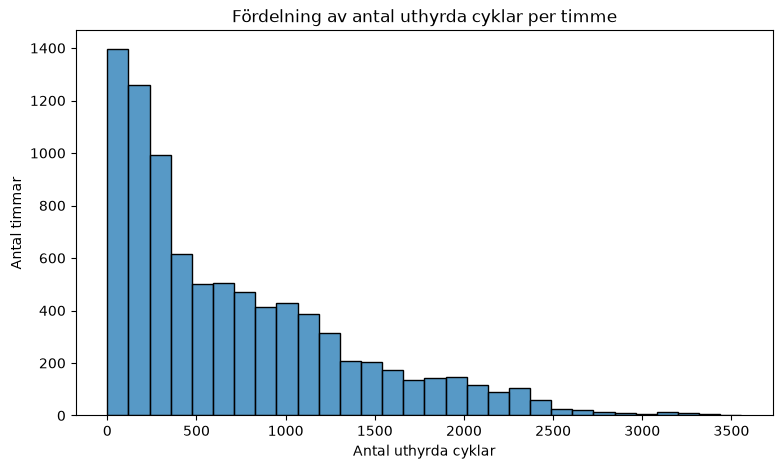

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Rented Bike Count", bins=30)

plt.title("Fördelning av antal uthyrda cyklar per timme")
plt.xlabel("Antal uthyrda cyklar")
plt.ylabel("Antal timmar")
plt.show()

**Diagrammet visar att timmar med låg uthyrning är vanligare än timmar med mycket hög uthyrning.**

---

In [12]:
df.groupby("Functioning Day")["Rented Bike Count"].agg(
    ["count", "min", "mean", "max"]
)

,count,min,mean,max
Functioning Day,,,,
No,295,0,0.000000,0
Yes,8465,2,729.156999,3556


In [13]:
df_open = df[df["Functioning Day"] == "Yes"].copy()

Vi fokuserar på uthyrning under timmar då systemet är i drift. Därför exkluderar vi 295 stängda timmar med noll uthyrningar. Dessa nollor visar att uthyrning inte var möjlig, snarare än att efterfrågan saknades.

---